# Global Oil & Gas Industry Analysis (1932–2014)
### Data Cleaning, Exploratory Data Analysis and Insights

**Project objective:** Explore historical country-level oil and natural gas production, prices, economic values, exports and population indicators from 1932 to 2014.

**Dataset:** `Oil and Gas 1932-2014.csv`  
**Scope:** Country-year observations. This is not field-level Abu Dhabi operational data.

## Notebook workflow
1. Import libraries and load data
2. Inspect data structure and quality
3. Clean and validate records
4. EDA and univariate analysis
5. Bivariate and multivariate analysis
6. Statistical analysis
7. Visualizations and insight generation
8. Feature engineering
9. Findings, limitations and recommendations

**Data-quality principle:** Missing values are not automatically converted to zero. Extreme values are flagged for investigation, not automatically removed, because large production and export values may be genuine.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')

## 2. Load the original dataset

In [2]:
# Place the original CSV in the same folder as this notebook.
file_path = Path('Oil and Gas 1932-2014.csv')
if not file_path.exists():
    file_path = Path('Oil_and_Gas_1932_2014_Cleaned.csv')

df_raw = pd.read_csv(file_path)
df = df_raw.copy()

print('Shape:', df.shape)
display(df.head())

Shape: (15521, 41)


,cty_name,iso3numeric,id,year,eiacty,oil_prod32_14,oil_price_2000,oil_price_nom,oil_value_nom,oil_value_2000,oil_value_2014,gas_prod55_14,gas_price_2000_mboe,gas_price_2000,gas_price_nom,gas_value_nom,gas_value_2000,gas_value_2014,oil_gas_value_nom,oil_gas_value_2000,oil_gas_value_2014,oil_gas_valuePOP_nom,oil_gas_valuePOP_2000,oil_gas_valuePOP_2014,oil_exports,net_oil_exports,net_oil_exports_mt,net_oil_exports_value,net_oil_exports_valuePOP,gas_exports,net_gas_exports_bcf,net_gas_exports_mboe,net_gas_exports_value,net_gas_exports_valuePOP,net_oil_gas_exports_valuePOP,population,pop_maddison,sovereign,mult_nom_2000,mult_nom_2014,mult_2000_2014
0,Afghanistan,4,AFG,1932,Afghanistan,NaN,10.861,0.870,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.600,17.322,1.375
1,Afghanistan,4,AFG,1933,Afghanistan,NaN,8.815,0.670,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,13.280,18.257,1.375
2,Afghanistan,4,AFG,1934,Afghanistan,NaN,12.716,1.000,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.853,17.670,1.375
3,Afghanistan,4,AFG,1935,Afghanistan,NaN,12.040,0.970,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.538,17.237,1.375
4,Afghanistan,4,AFG,1936,Afghanistan,NaN,13.383,1.090,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.421,17.076,1.375


## 3. Initial data inspection

In [3]:
display(df.info())
display(df.describe(include='all').T)
print('Duplicate rows:', df.duplicated().sum())
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({'missing_count': missing, 'missing_percent': missing_pct})
display(missing_report)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15521 entries, 0 to 15520
Data columns (total 41 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   cty_name                      15521 non-null  object 
 1   iso3numeric                   15521 non-null  int64  
 2   id                            15106 non-null  object 
 3   year                          15521 non-null  int64  
 4   eiacty                        14254 non-null  object 
 5   oil_prod32_14                 10103 non-null  float64
 6   oil_price_2000                15503 non-null  float64
 7   oil_price_nom                 15521 non-null  float64
 8   oil_value_nom                 10103 non-null  float64
 9   oil_value_2000                10103 non-null  float64
 10  oil_value_2014                10103 non-null  float64
 11  gas_prod55_14                 8812 non-null   float64
 12  gas_price_2000_mboe           15521 non-null  float64
 13  g

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
cty_name,15521,187,Afghanistan,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
iso3numeric,"15,521.000",NaN,NaN,NaN,440.102,266.690,4.000,204.000,422.000,694.000,998.000
id,15106,181,SDN,166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,"15,521.000",NaN,NaN,NaN,"1,973.000",23.959,"1,932.000","1,952.000","1,973.000","1,994.000","2,014.000"
eiacty,14254,173,Sudan,161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oil_prod32_14,"10,103.000",NaN,NaN,NaN,"18,341,081.948","63,849,380.421",0.000,0.000,"49,800.000","4,025,170.486","616,000,000.000"
oil_price_2000,"15,503.000",NaN,NaN,NaN,26.513,21.460,7.879,11.710,14.068,36.535,85.171
oil_price_nom,"15,521.000",NaN,NaN,NaN,19.407,27.820,0.670,1.800,3.290,25.023,111.670
oil_value_nom,"10,103.000",NaN,NaN,NaN,"4,049,736,832.823","20,178,007,363.851",0.000,0.000,"2,064,857.042","380,859,789.547","404,436,922,209.676"
oil_value_2000,"10,103.000",NaN,NaN,NaN,"4,777,023,320.153","21,001,223,150.101",0.000,0.000,"7,171,990.230","693,578,608.462","340,195,794,887.621"


Duplicate rows: 0


,missing_count,missing_percent
net_gas_exports_valuePOP,11646,75.030
net_oil_gas_exports_valuePOP,11646,75.030
net_gas_exports_value,11641,75.000
net_gas_exports_bcf,11505,74.130
net_gas_exports_mboe,11505,74.130
gas_exports,11503,74.110
net_oil_exports_valuePOP,11016,70.970
oil_exports,11011,70.940
net_oil_exports_value,11011,70.940
net_oil_exports,11011,70.940


## 4. Data cleaning

### Cleaning decisions
- Remove exact duplicate rows.
- Strip leading/trailing whitespace from text fields.
- Convert blank strings to missing values.
- Convert year, numeric country code and sovereignty flag to nullable integer types.
- Retain relevant columns; the supplied fields are relevant to the stated project.
- Preserve missing observations instead of blindly imputing zero or mean values.
- Check the year range against the dataset period (1932–2014).
- Detect potential outliers with the IQR rule; do not automatically delete valid country-scale extremes.

In [4]:
rows_before = len(df)
df = df.replace(r'^\\s*$', pd.NA, regex=True)

for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].astype('string').str.strip()

df = df.drop_duplicates().reset_index(drop=True)

for col in ['year', 'iso3numeric', 'sovereign']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')

if 'year' in df.columns:
    invalid_year = ~df['year'].between(1932, 2014)
    print('Invalid/out-of-period year values:', int(invalid_year.sum()))
    df.loc[invalid_year, 'year'] = pd.NA

print('Rows before:', rows_before)
print('Rows after:', len(df))
print('Exact duplicates removed:', rows_before-len(df))
display(df.head())

Invalid/out-of-period year values: 0
Rows before: 15521
Rows after: 15521
Exact duplicates removed: 0


,cty_name,iso3numeric,id,year,eiacty,oil_prod32_14,oil_price_2000,oil_price_nom,oil_value_nom,oil_value_2000,oil_value_2014,gas_prod55_14,gas_price_2000_mboe,gas_price_2000,gas_price_nom,gas_value_nom,gas_value_2000,gas_value_2014,oil_gas_value_nom,oil_gas_value_2000,oil_gas_value_2014,oil_gas_valuePOP_nom,oil_gas_valuePOP_2000,oil_gas_valuePOP_2014,oil_exports,net_oil_exports,net_oil_exports_mt,net_oil_exports_value,net_oil_exports_valuePOP,gas_exports,net_gas_exports_bcf,net_gas_exports_mboe,net_gas_exports_value,net_gas_exports_valuePOP,net_oil_gas_exports_valuePOP,population,pop_maddison,sovereign,mult_nom_2000,mult_nom_2014,mult_2000_2014
0,Afghanistan,4,AFG,1932,Afghanistan,NaN,10.861,0.870,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.600,17.322,1.375
1,Afghanistan,4,AFG,1933,Afghanistan,NaN,8.815,0.670,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,13.280,18.257,1.375
2,Afghanistan,4,AFG,1934,Afghanistan,NaN,12.716,1.000,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.853,17.670,1.375
3,Afghanistan,4,AFG,1935,Afghanistan,NaN,12.040,0.970,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.538,17.237,1.375
4,Afghanistan,4,AFG,1936,Afghanistan,NaN,13.383,1.090,NaN,NaN,NaN,NaN,0.000,NaN,0.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,12.421,17.076,1.375


### 4.1 Validate text and numeric columns

In [5]:
text_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
numeric_cols = df.select_dtypes(include='number').columns.tolist()
print('Text columns:', text_cols)
print('Numeric columns:', numeric_cols)
print('Year range:', df['year'].min(), 'to', df['year'].max())
print('Country count:', df['cty_name'].nunique())
print('Country-year duplicate keys:', df.duplicated(['cty_name', 'year']).sum())

Text columns: ['cty_name', 'id', 'eiacty']
Numeric columns: ['iso3numeric', 'year', 'oil_prod32_14', 'oil_price_2000', 'oil_price_nom', 'oil_value_nom', 'oil_value_2000', 'oil_value_2014', 'gas_prod55_14', 'gas_price_2000_mboe', 'gas_price_2000', 'gas_price_nom', 'gas_value_nom', 'gas_value_2000', 'gas_value_2014', 'oil_gas_value_nom', 'oil_gas_value_2000', 'oil_gas_value_2014', 'oil_gas_valuePOP_nom', 'oil_gas_valuePOP_2000', 'oil_gas_valuePOP_2014', 'oil_exports', 'net_oil_exports', 'net_oil_exports_mt', 'net_oil_exports_value', 'net_oil_exports_valuePOP', 'gas_exports', 'net_gas_exports_bcf', 'net_gas_exports_mboe', 'net_gas_exports_value', 'net_gas_exports_valuePOP', 'net_oil_gas_exports_valuePOP', 'population', 'pop_maddison', 'sovereign', 'mult_nom_2000', 'mult_nom_2014', 'mult_2000_2014']
Year range: 1932 to 2014
Country count: 187
Country-year duplicate keys: 0


### 4.2 Missing-value report

,missing_count,missing_percent
net_gas_exports_valuePOP,11646,75.030
net_oil_gas_exports_valuePOP,11646,75.030
net_gas_exports_value,11641,75.000
net_gas_exports_bcf,11505,74.130
net_gas_exports_mboe,11505,74.130
gas_exports,11503,74.110
net_oil_exports_valuePOP,11016,70.970
oil_exports,11011,70.940
net_oil_exports_value,11011,70.940
net_oil_exports,11011,70.940


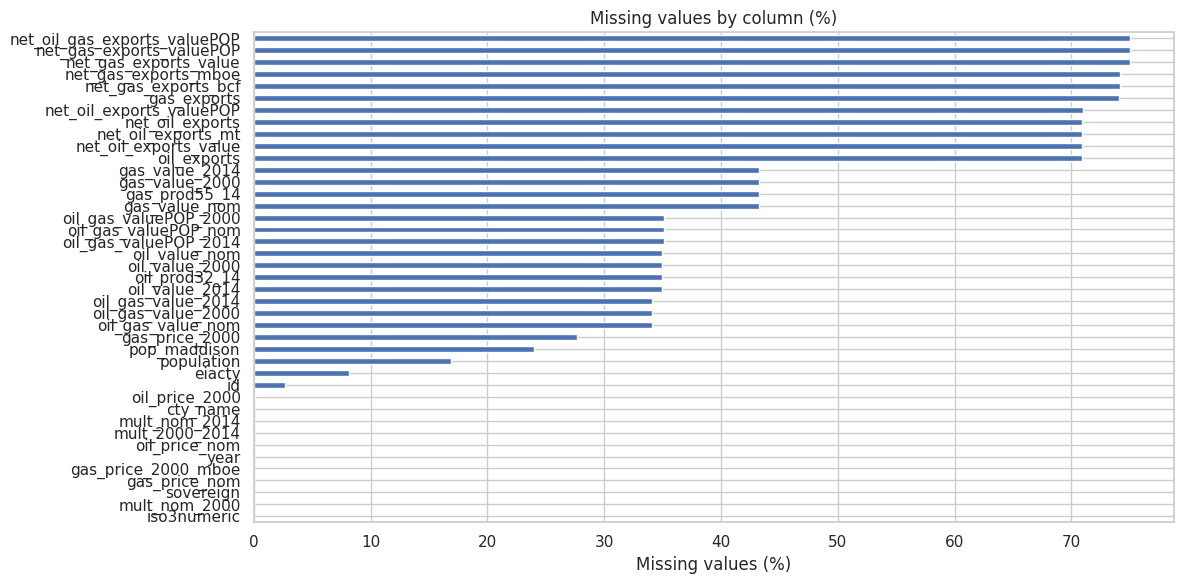

In [6]:
missing_report = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': (df.isna().mean()*100).round(2)
}).sort_values('missing_percent', ascending=False)
display(missing_report)
plt.figure(figsize=(12, 6))
missing_report['missing_percent'].sort_values().plot(kind='barh')
plt.title('Missing values by column (%)')
plt.xlabel('Missing values (%)')
plt.tight_layout()
plt.show()

### 4.3 Outlier detection (IQR)

In [7]:
# IQR flags are diagnostic only. Do not drop records automatically.
outlier_rows = []
for col in numeric_cols:
    s = df[col].dropna()
    if s.empty or s.nunique() < 4:
        continue
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3-q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    count = ((s < lower) | (s > upper)).sum()
    outlier_rows.append([col, lower, upper, int(count), round(count/len(s)*100,2)])
outlier_report = pd.DataFrame(outlier_rows, columns=['column','lower_bound','upper_bound','outlier_count','outlier_percent'])
display(outlier_report.sort_values('outlier_count', ascending=False))

,column,lower_bound,upper_bound,outlier_count,outlier_percent
15,oil_gas_value_nom,"-1,028,622,216.413","1,714,370,360.688",1965,19.200
19,oil_gas_valuePOP_2000,-116.871,194.785,1956,19.420
20,oil_gas_valuePOP_2014,-160.671,267.786,1956,19.420
18,oil_gas_valuePOP_nom,-74.479,124.132,1932,19.180
5,oil_value_nom,"-571,289,684.320","952,149,473.867",1929,19.090
7,oil_value_2014,"-1,430,270,256.557","2,383,783,760.928",1901,18.820
6,oil_value_2000,"-1,040,367,912.692","1,733,946,521.154",1901,18.820
17,oil_gas_value_2014,"-2,665,242,443.353","4,442,070,738.921",1874,18.310
16,oil_gas_value_2000,"-1,938,677,466.652","3,231,129,111.087",1874,18.310
2,oil_prod32_14,"-6,037,755.729","10,062,926.215",1805,17.870


### 4.4 Save cleaned dataset

In [8]:
# Save the cleaned dataset in the notebook's working directory.
# This avoids attempting to overwrite an uploaded/read-only input file.
cleaned_file = Path.cwd() / 'Oil_and_Gas_1932_2014_Cleaned.csv'
df.to_csv(cleaned_file, index=False)
print('Saved:', cleaned_file)
print('Final shape:', df.shape)

Saved: /mnt/data/Oil_and_Gas_1932_2014_Cleaned.csv
Final shape: (15521, 41)


## 5. Exploratory Data Analysis (EDA)

In [9]:
print('Countries:', df['cty_name'].nunique())
print('Years:', df['year'].min(), '-', df['year'].max())
print('Observations:', len(df))
display(df.groupby('year').size().describe())
display(df.groupby('cty_name').size().sort_values(ascending=False).head(10))

Countries: 187
Years: 1932 - 2014
Observations: 15521


count    83.000
mean    187.000
std       0.000
min     187.000
25%     187.000
50%     187.000
75%     187.000
max     187.000
dtype: float64

cty_name
Afghanistan     83
Albania         83
Algeria         83
Angola          83
Argentina       83
Armenia         83
Australia       83
Austria         83
Azerbaijan      83
Bahamas, The    83
dtype: int64

## 6. Univariate analysis

,count,mean,std,min,25%,50%,75%,max
oil_prod32_14,"10,103.000","18,341,081.948","63,849,380.421",0.000,0.000,"49,800.000","4,025,170.486","616,000,000.000"
gas_prod55_14,"8,812.000",100.702,462.242,0.000,0.000,0.000,21.684,"5,605.122"
oil_price_2000,"15,503.000",26.513,21.460,7.879,11.710,14.068,36.535,85.171
oil_price_nom,"15,521.000",19.407,27.820,0.670,1.800,3.290,25.023,111.670
oil_exports,"4,510.000",220.294,703.401,0.000,0.000,0.000,45.095,"7,477.621"
gas_exports,"4,018.000",149.518,674.677,0.000,0.000,0.000,0.000,"8,401.792"
population,"12,901.000","28,227,449.917","98,603,529.581","25,101.000","2,194,275.000","6,469,000.000","19,320,963.000","1,364,270,000.000"


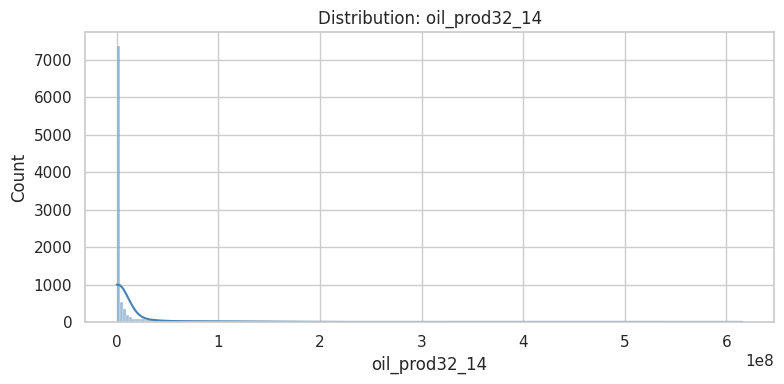

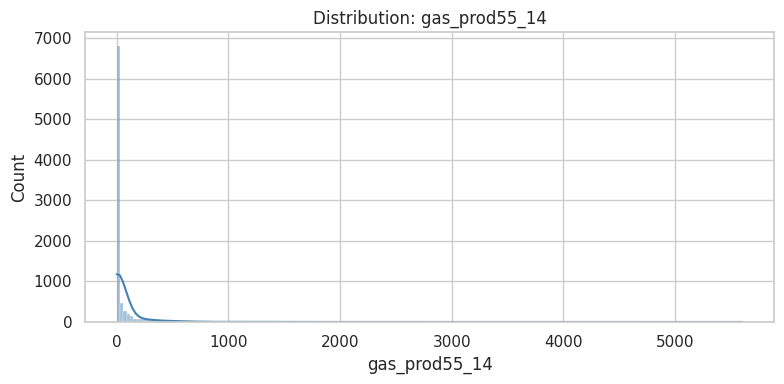

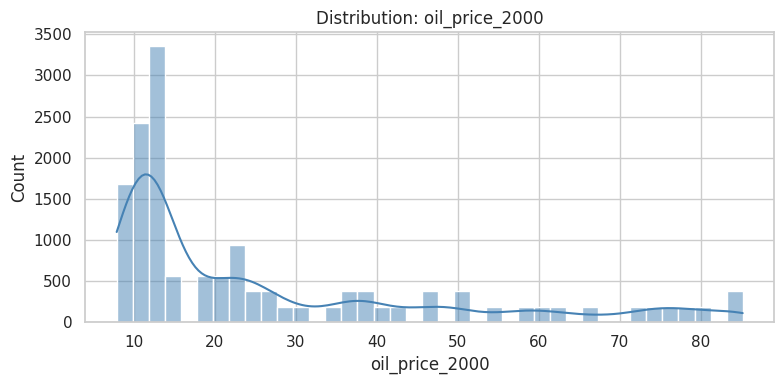

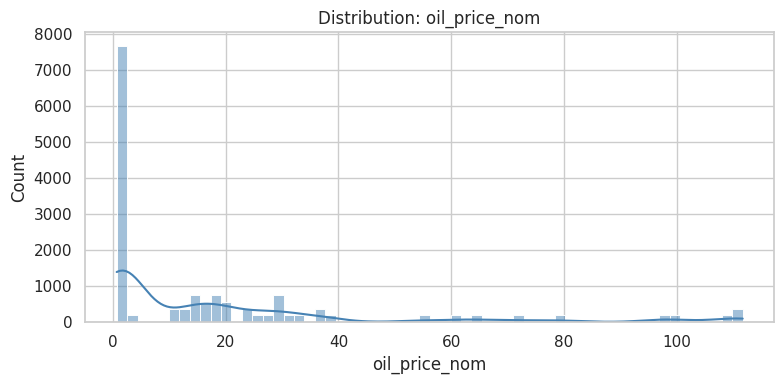

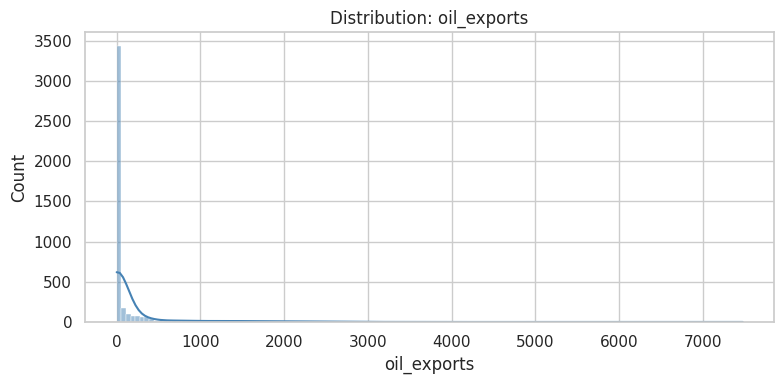

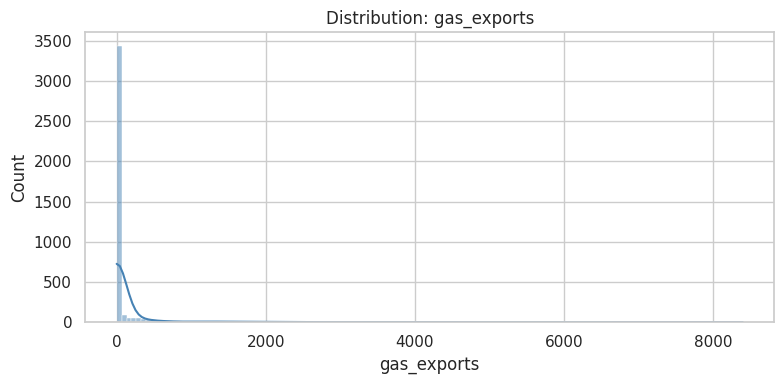

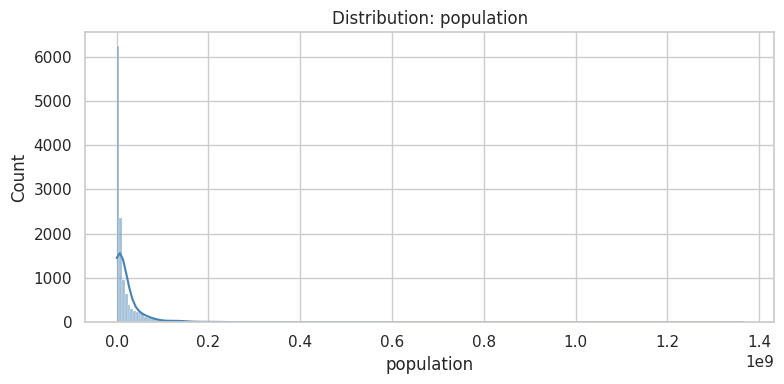

In [10]:
# Distribution summaries for selected measures
candidate_cols = ['oil_prod32_14', 'gas_prod55_14', 'oil_price_2000',
                  'oil_price_nom', 'oil_exports', 'gas_exports', 'population']
selected = [c for c in candidate_cols if c in df.columns]
display(df[selected].describe().T)
for col in selected:
    values = df[col].dropna()
    if values.empty:
        continue
    plt.figure(figsize=(8, 4))
    sns.histplot(values, kde=True, color='steelblue')
    plt.title(f'Distribution: {col}')
    plt.tight_layout()
    plt.show()

## 7. Bivariate analysis

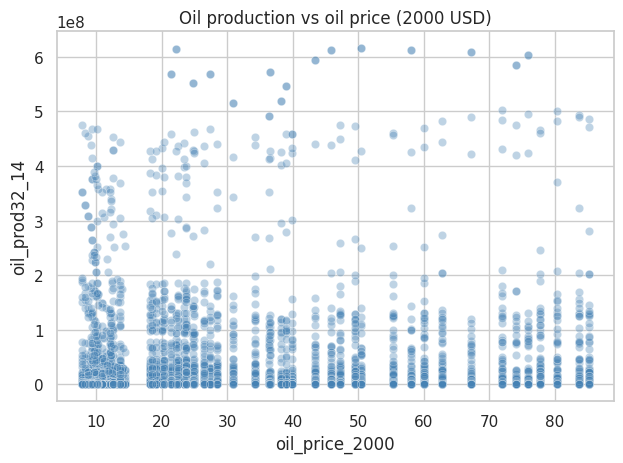

Pearson correlation: 0.04054413267351223


In [11]:
# Oil production and oil price relationship
if {'oil_prod32_14','oil_price_2000'}.issubset(df.columns):
    sample = df[['oil_prod32_14','oil_price_2000']].dropna()
    if len(sample):
        sns.scatterplot(data=sample, x='oil_price_2000', y='oil_prod32_14', alpha=.35, color='steelblue')
        plt.title('Oil production vs oil price (2000 USD)')
        plt.tight_layout()
        plt.show()
        print('Pearson correlation:', sample.corr().iloc[0,1])

## 8. Multivariate analysis

,oil_prod32_14,gas_prod55_14
cty_name,,
United States,"27,739,790,330.438","230,841.396"
Russian Federation,"24,401,401,376.486","166,099.952"
Saudi Arabia,"19,163,819,121.604","15,851.259"
Soviet Union,"14,671,000,000.000","75,046.012"
"Iran, Islamic Rep.","9,617,339,255.416","23,486.334"
"Venezuela, RB","9,180,202,526.408","14,266.451"
China,"6,295,581,384.366","9,640.698"
Kuwait,"6,167,662,426.116","3,244.451"
Mexico,"5,910,808,613.134","12,245.236"


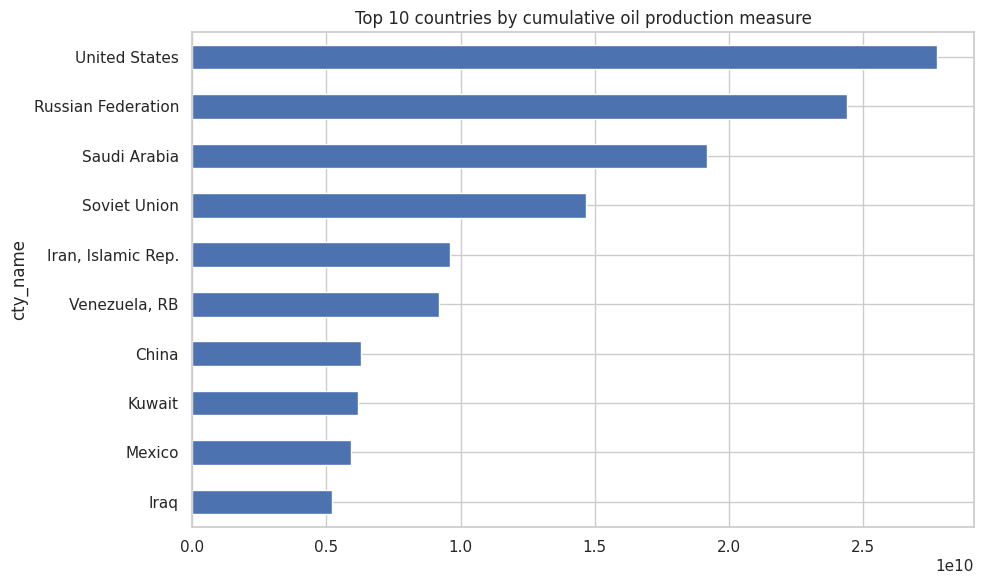

In [12]:
# Country-level aggregate comparison of production indicators
prod_cols = [c for c in ['oil_prod32_14','gas_prod55_14'] if c in df.columns]
if prod_cols:
    country_prod = df.groupby('cty_name')[prod_cols].sum(min_count=1)
    display(country_prod.sort_values(prod_cols[0], ascending=False).head(15))
    plt.figure(figsize=(10, 6))
    country_prod.sort_values(prod_cols[0], ascending=False).head(10)[prod_cols[0]].sort_values().plot(kind='barh')
    plt.title('Top 10 countries by cumulative oil production measure')
    plt.tight_layout()
    plt.show()

## 9. Statistical analysis

In [13]:
numeric_df = df.select_dtypes(include='number')
stats = numeric_df.agg(['count','mean','median','std','min','max']).T
display(stats)
# Mode is reported separately because a column can have multiple modes.
mode_report = {col: df[col].mode(dropna=True).head(3).tolist() for col in numeric_df.columns}
display(pd.Series(mode_report, name='mode_values').to_frame())

,count,mean,median,std,min,max
iso3numeric,"15,521.000",440.102,422.000,266.690,4.000,998.000
year,"15,521.000","1,973.000","1,973.000",23.959,"1,932.000","2,014.000"
oil_prod32_14,"10,103.000","18,341,081.948","49,800.000","63,849,380.421",0.000,"616,000,000.000"
oil_price_2000,"15,503.000",26.513,14.068,21.460,7.879,85.171
oil_price_nom,"15,521.000",19.407,3.290,27.820,0.670,111.670
oil_value_nom,"10,103.000","4,049,736,832.823","2,064,857.042","20,178,007,363.851",0.000,"404,436,922,209.676"
oil_value_2000,"10,103.000","4,777,023,320.153","7,171,990.230","21,001,223,150.101",0.000,"340,195,794,887.621"
oil_value_2014,"10,103.000","6,567,325,160.974","9,859,862.248","28,871,925,456.807",0.000,"467,692,170,142.369"
gas_prod55_14,"8,812.000",100.702,0.000,462.242,0.000,"5,605.122"
gas_price_2000_mboe,"15,521.000","14,035,974.900","14,721,586.756","11,020,086.388",0.000,"48,773,200.876"


,mode_values
iso3numeric,[736]
year,"[1932, 1933, 1934]"
oil_prod32_14,[0.0]
oil_price_2000,"[7.879107, 8.347174, 8.797903]"
oil_price_nom,[1.8]
oil_value_nom,[0.0]
oil_value_2000,[0.0]
oil_value_2014,[0.0]
gas_prod55_14,[0.0]
gas_price_2000_mboe,[0.0]


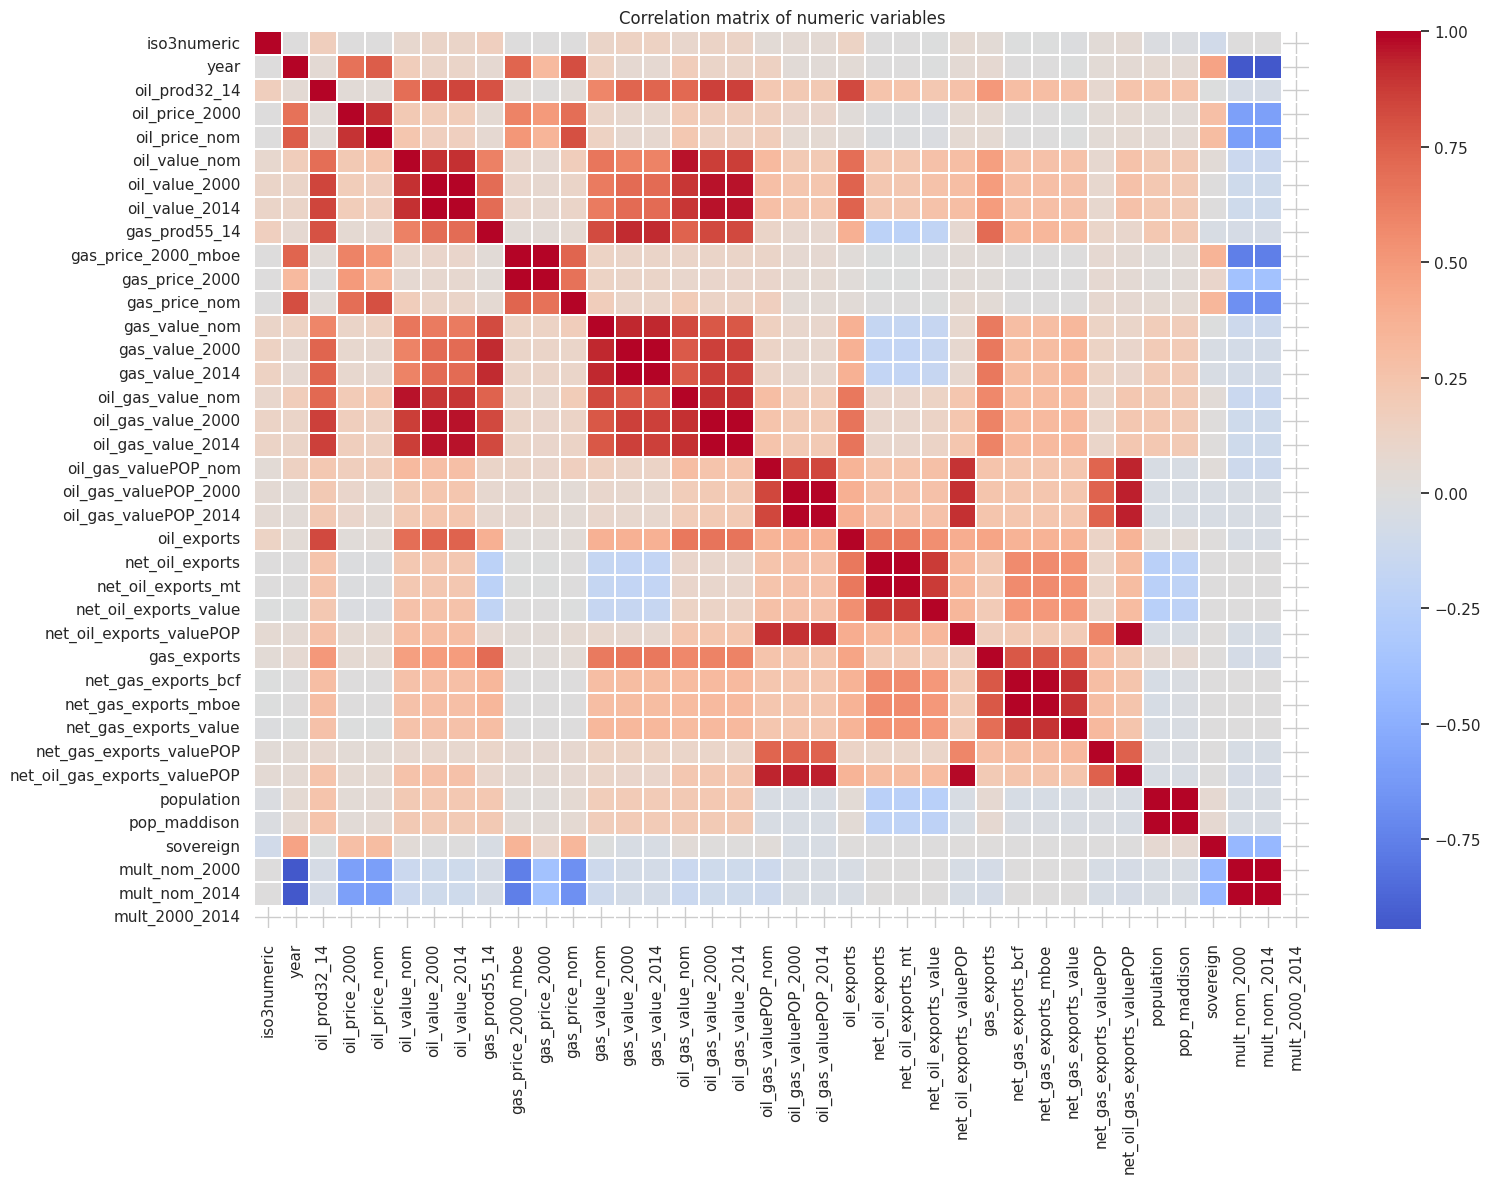

In [14]:
corr = numeric_df.corr(method='pearson')
plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=.2)
plt.title('Correlation matrix of numeric variables')
plt.tight_layout()
plt.show()

## 10. Data visualization – time trends

,oil_production,gas_production,oil_value,gas_value
year,,,,
1932,"200,389,023.300",0.000,"16,101,389,574.623",0.000
1933,"219,907,755.973",0.000,"14,342,322,778.462",0.000
1934,"231,752,482.230",0.000,"21,833,992,004.535",0.000
1935,"252,050,051.500",0.000,"22,469,151,762.405",0.000
1936,"274,152,748.800",0.000,"27,206,467,509.224",0.000


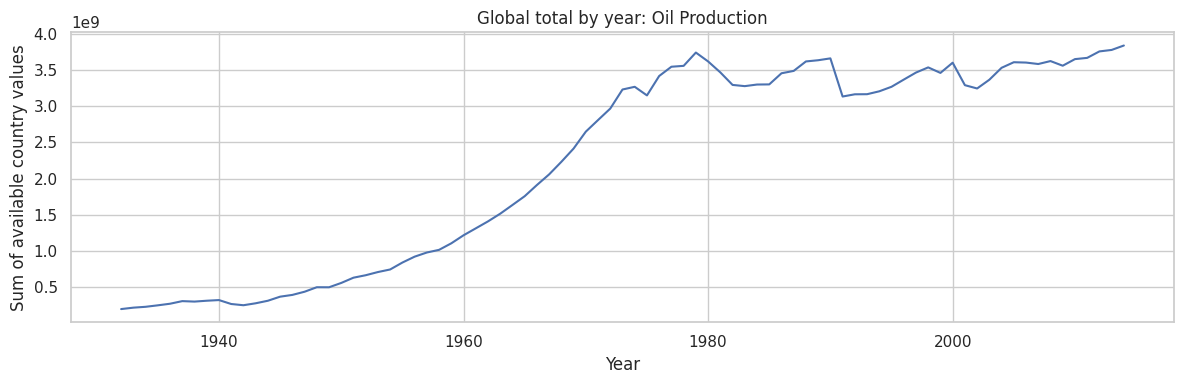

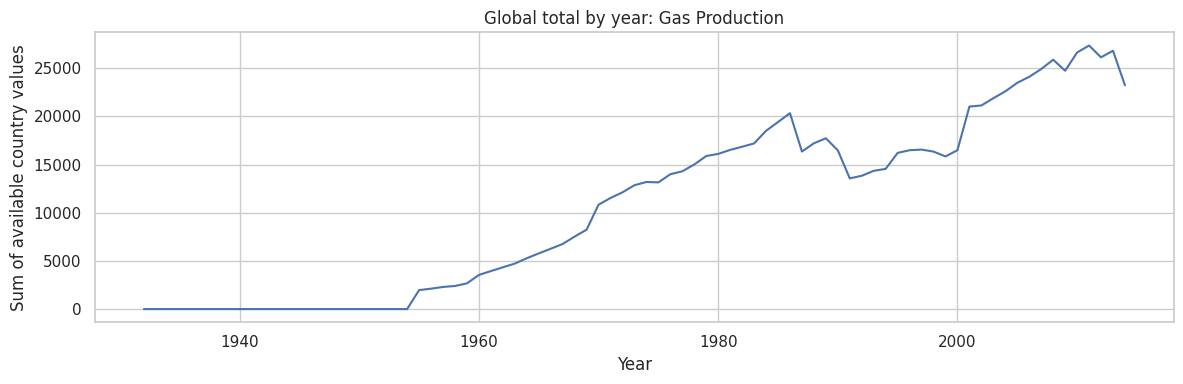

In [15]:
annual = df.groupby('year').agg(
    oil_production=('oil_prod32_14','sum'),
    gas_production=('gas_prod55_14','sum'),
    oil_value=('oil_value_2000','sum'),
    gas_value=('gas_value_2000','sum')
)
display(annual.head())
for col in ['oil_production','gas_production']:
    plt.figure(figsize=(12,4))
    annual[col].plot()
    plt.title(f'Global total by year: {col.replace("_", " ").title()}')
    plt.xlabel('Year')
    plt.ylabel('Sum of available country values')
    plt.tight_layout()
    plt.show()

## 11. Feature engineering

In [16]:
# Derived calendar and analytical features; original variables remain unchanged.
df['decade'] = (df['year'] // 10) * 10
df['oil_gas_production_total'] = df[['oil_prod32_14','gas_prod55_14']].sum(axis=1, min_count=1)
df['oil_gas_value_per_capita_2000'] = df['oil_gas_valuePOP_2000']
df['has_oil_production_record'] = df['oil_prod32_14'].notna().astype('int8')
df['has_gas_production_record'] = df['gas_prod55_14'].notna().astype('int8')
display(df[['cty_name','year','decade','oil_gas_production_total',
            'has_oil_production_record','has_gas_production_record']].head())

,cty_name,year,decade,oil_gas_production_total,has_oil_production_record,has_gas_production_record
0,Afghanistan,1932,1930,NaN,0,0
1,Afghanistan,1933,1930,NaN,0,0
2,Afghanistan,1934,1930,NaN,0,0
3,Afghanistan,1935,1930,NaN,0,0
4,Afghanistan,1936,1930,NaN,0,0


## 12. Insights and reporting

In [17]:
# Produce data-driven summary tables for the report.
if 'oil_prod32_14' in df:
    top_oil = df.groupby('cty_name')['oil_prod32_14'].sum(min_count=1).sort_values(ascending=False).head(10)
    print('Top countries by cumulative oil production measure:')
    display(top_oil.to_frame('oil_prod32_14_sum'))
if 'gas_prod55_14' in df:
    top_gas = df.groupby('cty_name')['gas_prod55_14'].sum(min_count=1).sort_values(ascending=False).head(10)
    print('Top countries by cumulative gas production measure:')
    display(top_gas.to_frame('gas_prod55_14_sum'))
print('Coverage by decade:')
display(df.groupby('decade').size().to_frame('observations'))

Top countries by cumulative oil production measure:


,oil_prod32_14_sum
cty_name,
United States,"27,739,790,330.438"
Russian Federation,"24,401,401,376.486"
Saudi Arabia,"19,163,819,121.604"
Soviet Union,"14,671,000,000.000"
"Iran, Islamic Rep.","9,617,339,255.416"
"Venezuela, RB","9,180,202,526.408"
China,"6,295,581,384.366"
Kuwait,"6,167,662,426.116"
Mexico,"5,910,808,613.134"


Top countries by cumulative gas production measure:


,gas_prod55_14_sum
cty_name,
United States,"230,841.396"
Russian Federation,"166,099.952"
Soviet Union,"75,046.012"
Canada,"45,192.482"
Algeria,"28,507.412"
"Iran, Islamic Rep.","23,486.334"
Netherlands,"21,824.476"
United Kingdom,"18,336.163"
Norway,"16,943.140"


Coverage by decade:


,observations
decade,
1930,1496
1940,1870
1950,1870
1960,1870
1970,1870
1980,1870
1990,1870
2000,1870
2010,935


## 13. Conclusions and future recommendations

Use the generated tables and charts to write conclusions supported by the actual results. Investigate:
- Which countries account for the largest cumulative oil and gas production measures?
- How did production and economic value change across decades?
- Which country-year observations have unusually high values, and are they valid?
- Are oil/gas production, exports, population and economic-value measures correlated?
- Where is data coverage weak because of missing observations?

### Recommended next steps
1. Validate definitions, units and methodology against the dataset documentation/source.
2. Investigate high-missingness export variables before drawing country comparisons.
3. Compare results using consistent country and year coverage.
4. Review flagged outliers against source records rather than deleting them automatically.
5. Consider time-series forecasting only after checking stationarity, coverage and structural breaks.
6. Keep country-level findings separate from field-level or Abu Dhabi-specific operational conclusions.

## 14. Limitations
- This dataset is country-level historical data, not individual oil-field production data.
- Missing values may reflect unavailable or unreported observations.
- The meaning and units of abbreviated source columns should be confirmed from the original dataset documentation before external publication.
- Correlation does not establish causation.